### this script plots the authorship representation

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gp
import matplotlib.colors as colors
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import os

In [2]:
pub_author_raw_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/pub_author.csv"
#pub_author_exp_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/pub_author_expected.csv"
pub_author_exp_path = "shuffle_exclusive_same_capacity.csv"
world_shp_path = "../../data/dropbox/LaborDivision/data/additionaldata/worldmap/ne_50m_admin_0_countries.shp"

pub_author_raw = pd.read_csv(pub_author_raw_path)
pub_author_exp = pd.read_csv(pub_author_exp_path)

### select publications that are collaborated by different scientific capacity groups

In [5]:
group_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'
group_df = pd.read_csv(group_path)
group_df = group_df.drop_duplicates()
group_df.head()

,Code,class
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [7]:
pub_author_raw = pub_author_raw.merge(group_df, left_on='cntry', right_on='Code', how='left')
pub_author_raw['unique_group'] = pub_author_raw.groupby(['ost_bk'])['class'].transform('nunique')
filtered_df = pub_author_raw[pub_author_raw.unique_group!=1]
filtered_df.head(2)

,ost_bk,cluster_id,cntry,role,year,dis,Code,class,unique_group
0,29768070,65683243.0,JPN,F,2008,51,JPN,Advanced,2
1,29768070,79129017.0,JPN,M,2008,51,JPN,Advanced,2


In [10]:
cntry_norm = get_normed_authorship(filtered_df, pub_author_exp)
cntry_norm['group'] = cntry_norm.apply(lambda x:map_group(x.F, x.L), axis=1)

In [9]:
def get_normed_authorship(raw_df, exp_df):
    cntry_raw = raw_df.groupby(['cntry','role']).size().reset_index(name='raw')
    cntry_exp = exp_df.groupby(['cntry','role'])['expected'].sum().reset_index(name='exp')
    cntry_all = cntry_raw.merge(cntry_exp, on=['cntry','role'])
    cntry_all['norm'] = cntry_all['raw']/cntry_all['exp']
    cntry_norm = cntry_all.pivot(index='cntry', columns='role', values='norm').reset_index()
    return cntry_norm

def map_group(fratio,lratio):
    if fratio<1 and lratio<1:
        return 0.5
    elif fratio>1 and lratio<1:
        return 1.5
    elif fratio<1 and lratio>1:
        return 2.5
    elif fratio>1 and lratio>1:
        return 3.5

In [11]:
def plot_worldmap(shp_path, df):
    world_geo=gp.read_file(shp_path)
    world_geo = world_geo[['ADMIN','NAME','ISO_A3','geometry']]
    world_geo=world_geo[world_geo.NAME!='Antarctica']
    world_geo.loc[world_geo.NAME=='France','ISO_A3']='FRA'
    world_geo.loc[world_geo.NAME=='Norway','ISO_A3']='NOR'
    
    colorsList = ['#D9D9D9', '#F4D05E', '#EA6B5F','#912855']
    cmap = colors.ListedColormap(colorsList)
    bounds = np.array([0, 1, 2, 3, 4])
    norm = colors.BoundaryNorm(boundaries=bounds, ncolors=4)
    
    fig, ax=plt.subplots(figsize=(16,6))
    world_geo.plot(ax = ax, linewidth=0.25, edgecolor="#8C8C8C", facecolor="#ffffff")
    df = df.merge(world_geo,left_on='cntry',right_on='ISO_A3')
    df = gp.GeoDataFrame(df)
    df.plot(column='group', cmap=cmap, norm=norm,ax=ax)
    ax.axis("off")
    return fig, ax

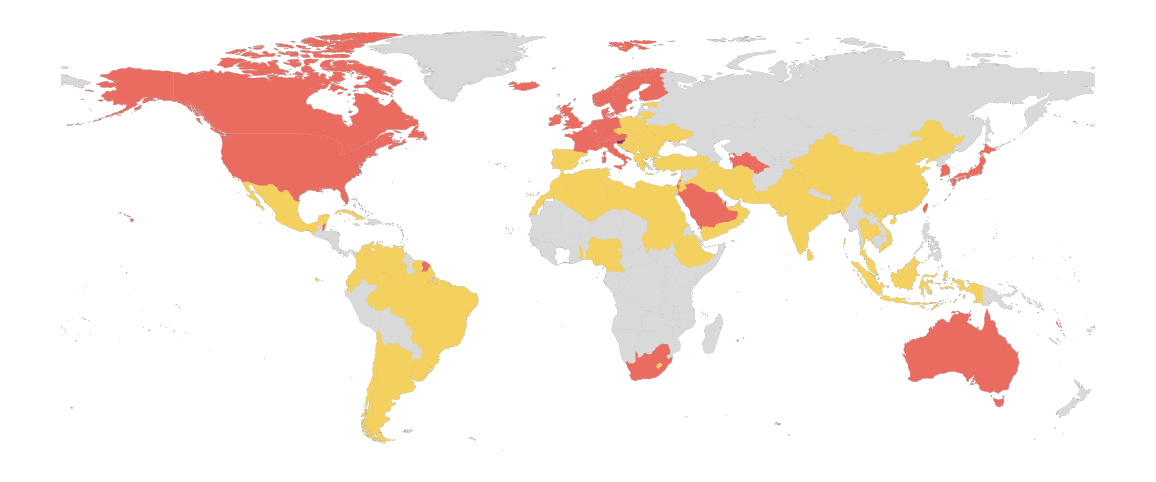

In [12]:
fig, ax = plot_worldmap(world_shp_path, cntry_norm)

Text(0, 0.5, 'Last Author')

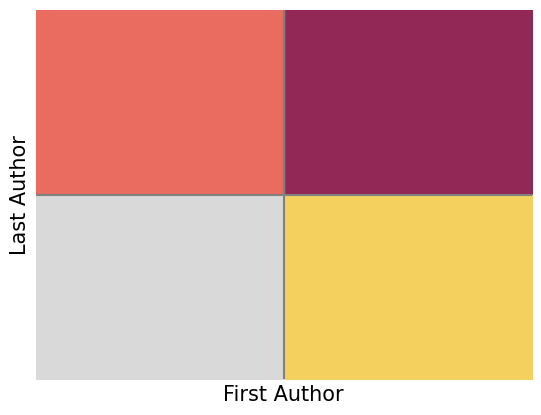

In [6]:
import matplotlib.pyplot as plt

# create a figure and axis object
fig, ax = plt.subplots()

# set the limits of the x and y axis
ax.set_xlim([-5, 5])
ax.set_ylim([-5, 5])

# draw the x and y axis
ax.axhline(y=0, color='gray')
ax.axvline(x=0, color='gray')

# fill the four quadrants with different colors
ax.fill_betweenx(y=[0, 5], x1=0, x2=5, color='#912855')
#ax.text(2.5, 2.5, 'Over_First\nOver_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[0, 5], x1=-5, x2=0, color='#EA6B5F')
#ax.text(-2.5, 2.5, 'Under_First\nOver_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[-5, 0], x1=0, x2=5, color='#F4D05E')
#ax.text(2.5, -2.5, 'Over_First\nUnder_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[-5, 0], x1=-5, x2=0, color='#D9D9D9')
#ax.text(-2.5, -2.5, 'Under_First\nUnder_Last', ha='center', va='center',fontsize=25, c='white')

ax.set_xticks([])
ax.set_yticks([])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlabel("First Author", fontsize=15)
ax.set_ylabel("Last Author", fontsize=15)

#plt.savefig(authorship_norm_plot_legend_path,bbox_inches='tight')

In [49]:
def get_normed_authorship(raw_df, exp_df):
    cntry_raw = raw_df.groupby(['cntry','year','role']).size().reset_index(name='raw')
    cntry_exp = exp_df.groupby(['cntry','year','role'])['expected'].sum().reset_index(name='exp')
    cntry_all = cntry_raw.merge(cntry_exp, on=['cntry','year','role'])
    cntry_all['norm'] = np.log(cntry_all['raw']/cntry_all['exp'])
    #cntry_norm = cntry_all.pivot(index='cntry', columns='role', values='norm').reset_index()
    
    return cntry_all

def plot_line(data,authorship,ax,title, color_dict):
    df=data[data.role==authorship]
    sns.lineplot(x='year',y='norm',hue='class',data=df,ax=ax,legend=False,
             palette=color_dict)
    ax.axhline(y=0, color='#A1A1A6', linestyle='--')
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title,fontsize=12)
    ax.set_ylim(-0.45, 0.25)
    return ax

def plot(df, color_dict):
    
    fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(16,5))
    ax0=plot_line(df,'F',ax[0],'First Author', color_dict)
    ax1=plot_line(df,'M',ax[1],'Middle Author', color_dict)
    ax2=plot_line(df,'L',ax[2],'Last Author', color_dict)

   
    lines = [Line2D([0], [0], color=v, linewidth=3, linestyle='-', label=k) for k,v in color_dict.items()]
    plt.legend(handles=lines, frameon=False)
    
    fig.text(x=0.45,y=0.01,s="Year of publication",fontsize=15)
    ax0.set_ylabel("Log normalized occurance of authorship",fontsize=15)
    return fig, ax

In [23]:
pub_author_raw_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/pub_author.csv"
#pub_author_exp_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/pub_author_expected.csv"
pub_author_exp_path = "shuffle_exclusive_same_capacity.csv"
stgroup_path = "../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv"
color_scheme_path = "../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/color_scheme.csv"

pub_author_raw = pd.read_csv(pub_author_raw_path)
pub_author_exp = pd.read_csv(pub_author_exp_path)


In [48]:
stgroup = pd.read_csv(stgroup_path)
color_scheme = pd.read_csv(color_scheme_path)

#distinguish the classification system (st, income) and then retrieve the corrosponding color scheme
classify_type = os.path.splitext(os.path.basename(stgroup_path))[0].split("_")[1]
color_filter = color_scheme[color_scheme.type==classify_type]
color_dict = dict(zip(color_filter['class'], color_filter['color']))

In [31]:
cntry_norm = get_normed_authorship(filtered_df, pub_author_exp)
cntry_norm = cntry_norm.merge(stgroup, left_on='cntry', right_on='Code')

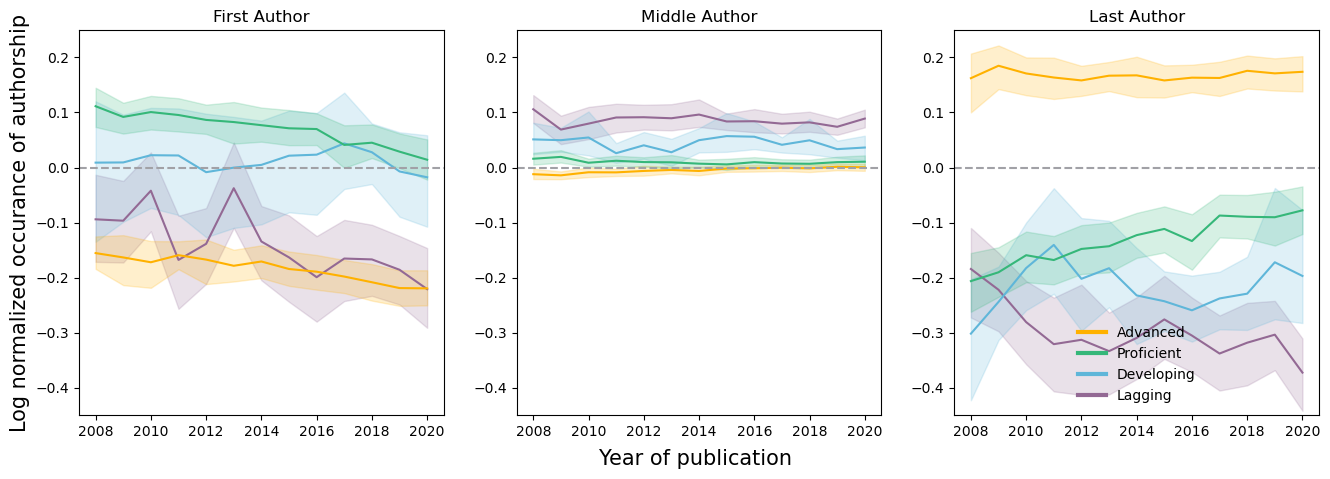

In [50]:
fig, ax = plot(cntry_norm, color_dict)